# Bank Loan Analysis

### Import the required libraries

In [2]:
!pip install plotly

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   --- ------------------------------------ 0.8/9.7 MB 7.1 MB/s eta 0:00:02
   --------- ------------------------------ 2.4/9.7 MB 6.3 MB/s eta 0:00:02
   ------------ --------------------------- 3.1/9.7 MB 5.7 MB/s eta 0:00:02
   --------------- ------------------------ 3.7/9.7 MB 5.0 MB/s eta 0:00:02
   ----------------- ---------------------- 4.2/9.7 MB 4.5 MB/s eta 0:00:02
   -------------------- ------------------- 5.0/9.7 MB 4.2 MB/s eta 0:00:02
   ----------------------- ---------------- 5.8/9.7 MB 4.2 MB/s eta 0:00:01
   --------------------------- ------------ 6.6/9.7 MB 4.2 MB/s eta 0:00:01
   ------------------------------ --------- 7.3/9.7 MB 4.0 MB/s eta 0:00:01
   -------------------------------- ------- 7.9/9.7 MB 3.8 MB/s eta 0:00:01
   ----------------------------------- ---- 8.7/9.7 MB 3.8 MB/s eta 0:00:01
   --------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import plotly.express as px

In [3]:
df = pd.read_excel("C:/Users/Admin/Downloads/financial_loan.xlsx")

In [6]:
df.head()

,id,address_state,application_type,emp_length,emp_title,grade,home_ownership,issue_date,last_credit_pull_date,last_payment_date,...,sub_grade,term,verification_status,annual_income,dti,installment,int_rate,loan_amount,total_acc,total_payment
0,1077430,GA,INDIVIDUAL,< 1 year,Ryder,C,RENT,2021-02-11,2021-09-13,2021-04-13,...,C4,60 months,Source Verified,30000.0,0.0100,59.83,0.1527,2500,4,1009
1,1072053,CA,INDIVIDUAL,9 years,MKC Accounting,E,RENT,2021-01-01,2021-12-14,2021-01-15,...,E1,36 months,Source Verified,48000.0,0.0535,109.43,0.1864,3000,4,3939
2,1069243,CA,INDIVIDUAL,4 years,Chemat Technology Inc,C,RENT,2021-01-05,2021-12-12,2021-01-09,...,C5,36 months,Not Verified,50000.0,0.2088,421.65,0.1596,12000,11,3522
3,1041756,TX,INDIVIDUAL,< 1 year,barnes distribution,B,MORTGAGE,2021-02-25,2021-12-12,2021-03-12,...,B2,60 months,Source Verified,42000.0,0.0540,97.06,0.1065,4500,9,4911
4,1068350,IL,INDIVIDUAL,10+ years,J&J Steel Inc,A,MORTGAGE,2021-01-01,2021-12-14,2021-01-15,...,A1,36 months,Verified,83000.0,0.0231,106.53,0.0603,3500,28,3835


In [7]:
df.tail()

,id,address_state,application_type,emp_length,emp_title,grade,home_ownership,issue_date,last_credit_pull_date,last_payment_date,...,sub_grade,term,verification_status,annual_income,dti,installment,int_rate,loan_amount,total_acc,total_payment
38571,803452,NJ,INDIVIDUAL,< 1 year,Joseph M Sanzari Company,C,MORTGAGE,2021-07-11,2021-05-16,2021-05-16,...,C1,60 months,Verified,100000.0,0.1986,551.64,0.1299,24250,33,31946
38572,970377,NY,INDIVIDUAL,8 years,Swat Fame,C,RENT,2021-10-11,2021-04-16,2021-05-16,...,C1,60 months,Verified,50000.0,0.0458,579.72,0.1349,25200,18,31870
38573,875376,CA,INDIVIDUAL,5 years,Anaheim Regional Medical Center,D,RENT,2021-09-11,2021-05-16,2021-05-16,...,D5,60 months,Verified,65000.0,0.1734,627.93,0.1749,25000,20,35721
38574,972997,NY,INDIVIDUAL,5 years,Brooklyn Radiology,D,RENT,2021-10-11,2021-05-16,2021-05-16,...,D5,60 months,Verified,368000.0,0.0009,612.72,0.1825,24000,9,33677
38575,682952,NY,INDIVIDUAL,4 years,Allen Edmonds,F,RENT,2021-07-11,2021-05-16,2021-05-16,...,F3,60 months,Verified,80000.0,0.0600,486.86,0.2099,18000,7,27679


### Dataset Info

In [8]:
print("No of Rows:", df.shape[0])

No of Rows: 38576


In [9]:
print("No of Columns:", df.shape[1])

No of Columns: 24


In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 38576 entries, 0 to 38575
Data columns (total 24 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   id                     38576 non-null  int64         
 1   address_state          38576 non-null  str           
 2   application_type       38576 non-null  str           
 3   emp_length             38576 non-null  str           
 4   emp_title              37138 non-null  object        
 5   grade                  38576 non-null  str           
 6   home_ownership         38576 non-null  str           
 7   issue_date             38576 non-null  datetime64[us]
 8   last_credit_pull_date  38576 non-null  datetime64[us]
 9   last_payment_date      38576 non-null  datetime64[us]
 10  loan_status            38576 non-null  str           
 11  next_payment_date      38576 non-null  datetime64[us]
 12  member_id              38576 non-null  int64         
 13  purpose     

### Datatypes Info

In [13]:
df.dtypes

id                                int64
address_state                       str
application_type                    str
emp_length                          str
emp_title                        object
grade                               str
home_ownership                      str
issue_date               datetime64[us]
last_credit_pull_date    datetime64[us]
last_payment_date        datetime64[us]
loan_status                         str
next_payment_date        datetime64[us]
member_id                         int64
purpose                             str
sub_grade                           str
term                                str
verification_status                 str
annual_income                   float64
dti                             float64
installment                     float64
int_rate                        float64
loan_amount                       int64
total_acc                         int64
total_payment                     int64
dtype: object

In [14]:
df.describe()

,id,issue_date,last_credit_pull_date,last_payment_date,next_payment_date,member_id,annual_income,dti,installment,int_rate,loan_amount,total_acc,total_payment
count,3.857600e+04,38576,38576,38576,38576,3.857600e+04,3.857600e+04,38576.000000,38576.000000,38576.000000,38576.000000,38576.000000,38576.000000
mean,6.810371e+05,2021-07-16 02:31:35.562007,2021-06-08 13:36:34.193280,2021-06-26 09:52:08.909166,2021-07-26 20:42:20.605557,8.476515e+05,6.964454e+04,0.133274,326.862965,0.120488,11296.066855,22.132544,12263.348533
min,5.473400e+04,2021-01-01 00:00:00,2021-01-08 00:00:00,2021-01-08 00:00:00,2021-02-08 00:00:00,7.069900e+04,4.000000e+03,0.000000,15.690000,0.054200,500.000000,2.000000,34.000000
25%,5.135170e+05,2021-04-11 00:00:00,2021-04-15 00:00:00,2021-03-16 00:00:00,2021-04-16 00:00:00,6.629788e+05,4.150000e+04,0.082100,168.450000,0.093200,5500.000000,14.000000,5633.000000
50%,6.627280e+05,2021-07-11 00:00:00,2021-05-16 00:00:00,2021-06-14 00:00:00,2021-07-14 00:00:00,8.473565e+05,6.000000e+04,0.134200,283.045000,0.118600,10000.000000,20.000000,10042.000000
75%,8.365060e+05,2021-10-11 00:00:00,2021-08-13 00:00:00,2021-09-15 00:00:00,2021-10-15 00:00:00,1.045652e+06,8.320050e+04,0.185900,434.442500,0.145900,15000.000000,29.000000,16658.000000
max,1.077501e+06,2021-12-12 00:00:00,2022-01-20 00:00:00,2021-12-15 00:00:00,2022-01-15 00:00:00,1.314167e+06,6.000000e+06,0.299900,1305.190000,0.245900,35000.000000,90.000000,58564.000000
std,2.113246e+05,NaN,NaN,NaN,NaN,2.668105e+05,6.429368e+04,0.066662,209.092000,0.037164,7460.746022,11.392282,9051.104777


## KPI Calculations

### 1. Total Loan Applications

In [16]:
total_loan_application = df["id"].count()
print("Total Loan Applications:", total_loan_application)

Total Loan Applications: 38576


### 2. MTD Total Loan Applications

In [21]:
latest_issue_date = df["issue_date"].max
latest_year = latest_issue_date().year
latest_month = latest_issue_date().month

mtd_data = df[(df["issue_date"].dt.year == latest_year) & (df["issue_date"].dt.month == latest_month)]

mtd_loan_applications = mtd_data["id"].count()

print(f"MTD Loan Applications:{mtd_loan_applications}") # Output will be shown for latest month loan applications i.e December as per dataset

latest_issue_date
MTD Loan Applications:4314


### 3. Total Funded Amount

In [31]:
total_funded_amount = df["loan_amount"].sum()
total_funded_amount_millions = total_funded_amount/1000000
print(f"Total Funded Amount: ${total_funded_amount_millions:.2f} M")

Total Funded Amount: $435.76 M


### 4. MTD Total Funded Amount

In [34]:
latest_issue_date = df["issue_date"].max
latest_year = latest_issue_date().year
latest_month = latest_issue_date().month

mtd_data = df[(df["issue_date"].dt.year == latest_year) & (df["issue_date"].dt.month == latest_month)]

mtd_total_funded_amount = mtd_data["loan_amount"].sum()
mtd_total_funded_amount_millions = mtd_total_funded_amount/1000000
print(f"MTD Total Funded Amount: ${mtd_total_funded_amount_millions:.2f} M") 
# It will show the total amount funded in last month i.e. December as per dataset

MTD Total Funded Amount: $53.98 M


### 5. Total Amount Received

In [35]:
total_amount_received = df["total_payment"].sum()
total_amount_received_millions = total_amount_received/1000000
print(f"Total Amount Received: ${total_amount_received_millions:.2f} M")

Total Amount Received: $473.07 M


### 6. MTD Total Amount Received

In [37]:
latest_issue_date = df["issue_date"].max
latest_year = latest_issue_date().year
latest_month = latest_issue_date().month

mtd_data = df[(df["issue_date"].dt.year == latest_year) & (df["issue_date"].dt.month == latest_month)]

mtd_total_amount_received = mtd_data["total_payment"].sum()
mtd_total_amount_received_millions = mtd_total_amount_received/1000000
print(f"MTD Total Amount Received: ${mtd_total_amount_received_millions:.2f} M") 
# It will show the total amount received in last month i.e. December as per dataset

MTD Total Amount Received: $58.07 M


### 7. Average Interest Rate

In [44]:
average_interest_rate = df["int_rate"].mean()*100
print(f"Avg. Interest Rate: {average_interest_rate:.2f} %")

Avg. Interest Rate: 12.05 %


### 8. Average Debt to Income Ratio (DTI)

In [46]:
average_dti = df["dti"].mean()*100
print(f"Avg. DTI: {average_dti:.2f} %")

Avg. DTI: 13.33 %


## Good Loan Metrics

In [51]:
good_loans = df[df['loan_status'].isin(["Fully Paid", "Current"])]

total_loan_applications = df['id'].count()

good_loan_applications = good_loans['id'].count()
good_loan_funded_amount = good_loans['loan_amount'].sum()
good_loan_received = good_loans['total_payment'].sum()

good_loan_funded_amount_millions = good_loan_funded_amount / 1000000
good_loan_received_millions = good_loan_received / 1000000

good_loan_percentage = (good_loan_applications / total_loan_applications) * 100

print(f"Good Loan Applications: {good_loan_applications}")
print(f"Good Loan Funded Amount (in Millions): ${good_loan_funded_amount_millions:.2f} M")
print(f"Good Loan Total Received (in Millions): ${good_loan_received_millions:.2f} M")
print(f"Percentage of Good Loan Applications: {good_loan_percentage:.2f}%")

Good Loan Applications: 33243
Good Loan Funded Amount (in Millions): $370.22 M
Good Loan Total Received (in Millions): $435.79 M
Percentage of Good Loan Applications: 86.18%


## Bad Loan Metrics

In [52]:
bad_loans = df[df['loan_status'] == "Charged Off"]

bad_loan_applications = bad_loans['id'].count()
bad_loan_funded_amount = bad_loans['loan_amount'].sum()
bad_loan_received = bad_loans['total_payment'].sum()

bad_loan_funded_amount_millions = bad_loan_funded_amount / 1000000
bad_loan_received_millions = bad_loan_received / 1000000

bad_loan_percentage = (bad_loan_applications / total_loan_applications) * 100

print(f"Bad Loan Applications: {bad_loan_applications}")
print(f"Bad Loan Funded Amount (in Millions): ${bad_loan_funded_amount_millions:.2f} M")
print(f"Bad Loan Total Received (in Millions): ${bad_loan_received_millions:.2f} M")
print(f"Percentage of Bad Loan Applications: {bad_loan_percentage:.2f}%")

Bad Loan Applications: 5333
Bad Loan Funded Amount (in Millions): $65.53 M
Bad Loan Total Received (in Millions): $37.28 M
Percentage of Bad Loan Applications: 13.82%


### Monthly Trends by Issue Date for Total Funded Amount

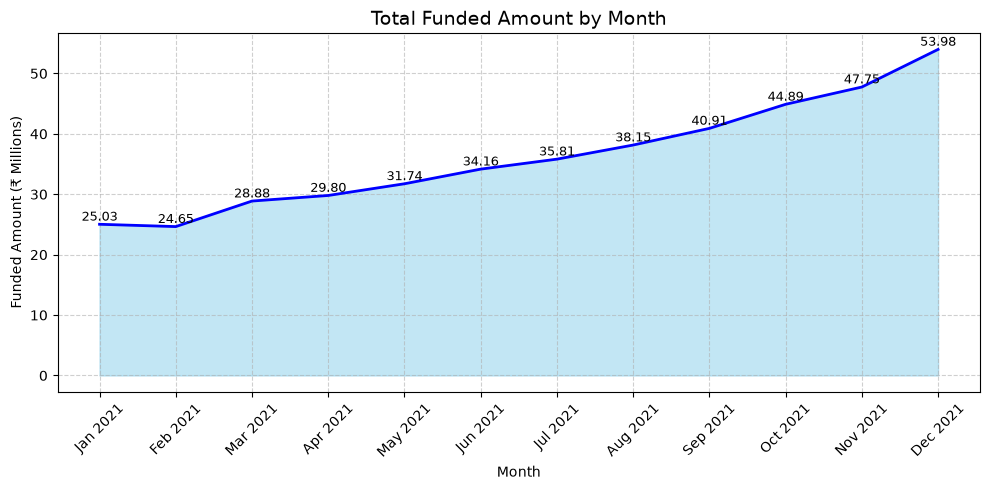

In [4]:
monthly_funded = (
    df.sort_values('issue_date')
    .assign(month_name=lambda x: x['issue_date'].dt.strftime('%b %Y'))
    .groupby('month_name', sort=False)['loan_amount']
    .sum()
    .div(1000000)
    .reset_index(name='loan_amount_millions')
)

plt.figure(figsize=(10, 5))
plt.fill_between(monthly_funded['month_name'], monthly_funded['loan_amount_millions'], color='skyblue', alpha=0.5)
plt.plot(monthly_funded['month_name'], monthly_funded['loan_amount_millions'], color='blue', linewidth=2)

for i, row in monthly_funded.iterrows():
    plt.text(i, row['loan_amount_millions'] + 0.1, f"{row['loan_amount_millions']:.2f}",
             ha='center', va='bottom', fontsize=9, rotation=0, color='black')

plt.title('Total Funded Amount by Month', fontsize=14)
plt.xlabel('Month')
plt.ylabel('Funded Amount (₹ Millions)')
plt.xticks(ticks=range(len(monthly_funded)), labels=monthly_funded['month_name'], rotation=45)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

### Monthly Trends by Issue Date for Total Amount Received

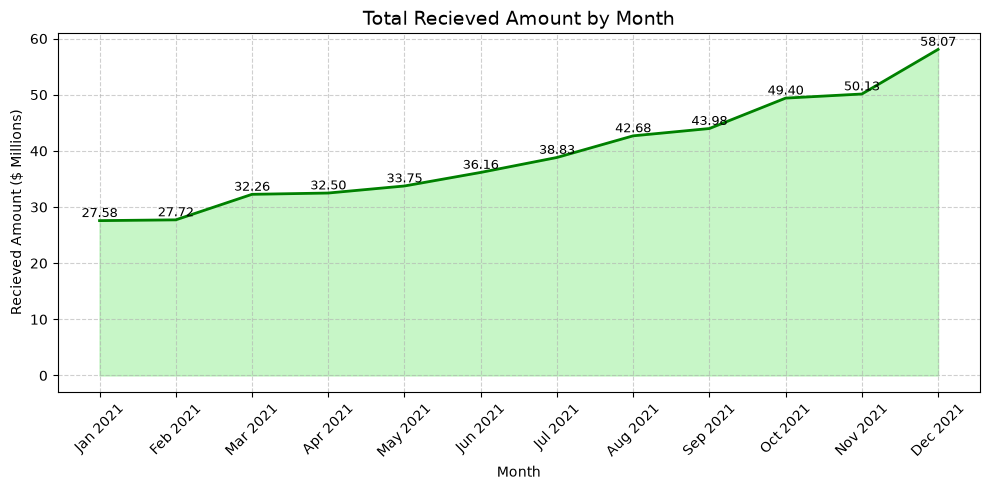

In [60]:
monthly_recieved = (
    df.sort_values('issue_date')
    .assign(month_name=lambda x: x['issue_date'].dt.strftime('%b %Y'))
    .groupby('month_name', sort=False)['total_payment']
    .sum()
    .div(1_000_000)
    .reset_index(name='total_payment_millions')
)

plt.figure(figsize=(10, 5))
plt.fill_between(monthly_recieved['month_name'], monthly_recieved['total_payment_millions'], color='lightgreen', alpha=0.5)
plt.plot(monthly_recieved['month_name'], monthly_recieved['total_payment_millions'], color='green', linewidth=2)

for i, row in monthly_recieved.iterrows():
    plt.text(i, row['total_payment_millions'] + 0.1, f"{row['total_payment_millions']:.2f}",
             ha='center', va='bottom', fontsize=9, rotation=0, color='black')

plt.title('Total Recieved Amount by Month', fontsize=14)
plt.xlabel('Month')
plt.ylabel('Recieved Amount ($ Millions)')
plt.xticks(ticks=range(len(monthly_recieved)), labels=monthly_recieved['month_name'], rotation=45)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

### Monthly Trends by Issue Date for Total Loan Applications

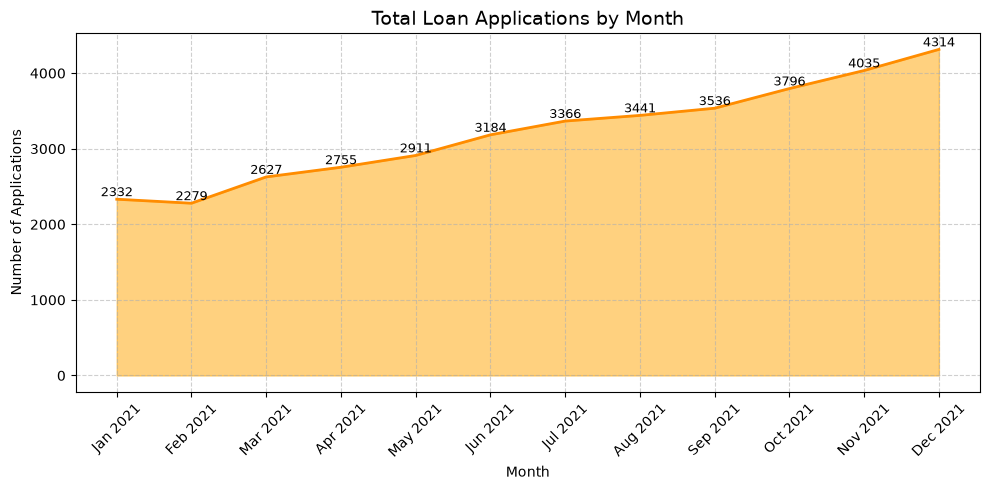

In [61]:
monthly_applications = (
    df.sort_values('issue_date')
      .assign(month_name=lambda x: x['issue_date'].dt.strftime('%b %Y'))
      .groupby('month_name', sort=False)['id']
      .count()
      .reset_index(name='loan_applications_count')
)

plt.figure(figsize=(10, 5))
plt.fill_between(monthly_applications['month_name'], monthly_applications['loan_applications_count'],
                 color='orange', alpha=0.5)
plt.plot(monthly_applications['month_name'], monthly_applications['loan_applications_count'],
         color='darkorange', linewidth=2)

for i, row in monthly_applications.iterrows():
    plt.text(i, row['loan_applications_count'] + 0.5, f"{row['loan_applications_count']}",
             ha='center', va='bottom', fontsize=9, rotation=0, color='black')

plt.title('Total Loan Applications by Month', fontsize=14)
plt.xlabel('Month')
plt.ylabel('Number of Applications')
plt.xticks(ticks=range(len(monthly_applications)), labels=monthly_applications['month_name'], rotation=45)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

### Regional Analysis by State for Total Funded Amount

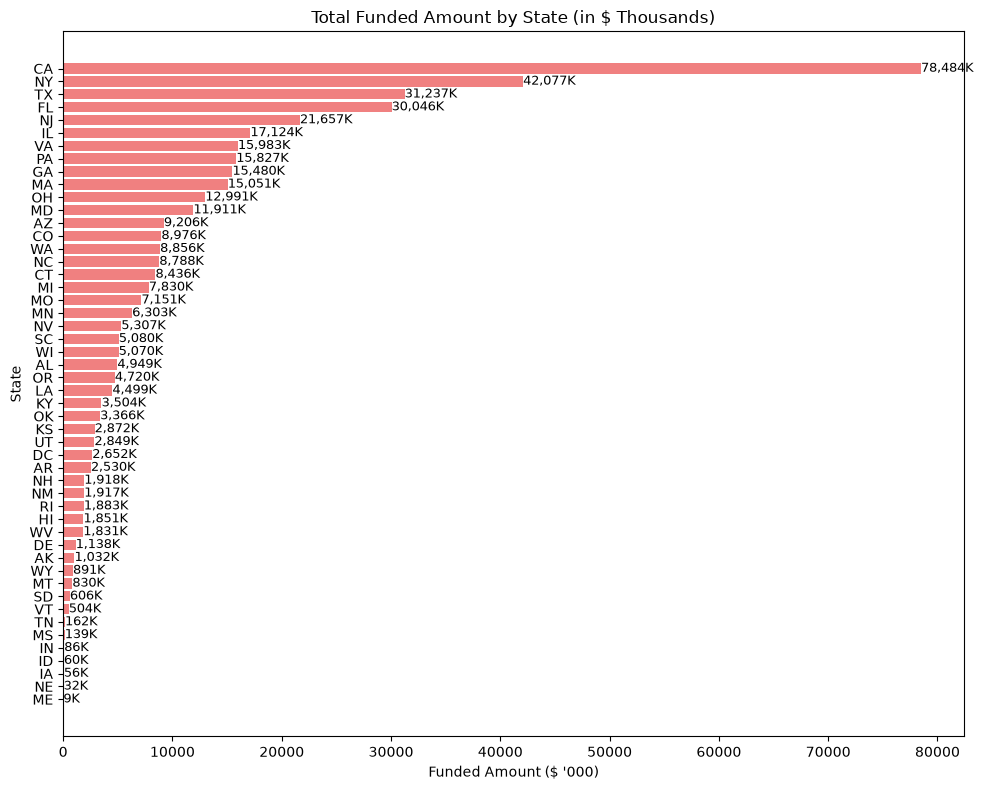

In [68]:
state_funding = df.groupby('address_state')['loan_amount'].sum().sort_values(ascending=True)
state_funding_thousands = state_funding / 1000

plt.figure(figsize=(10, 8))
bars = plt.barh(state_funding_thousands.index, state_funding_thousands.values, color='lightcoral')

for bar in bars:
    width = bar.get_width()
    plt.text(width + 10, bar.get_y() + bar.get_height() / 2,
             f'{width:,.0f}K', va='center', fontsize=9)

plt.title('Total Funded Amount by State (in $ Thousands)')
plt.xlabel('Funded Amount ($ \'000)')
plt.ylabel('State')
plt.tight_layout()
plt.show()

### Loan Term Analysis by Total Funded Amount

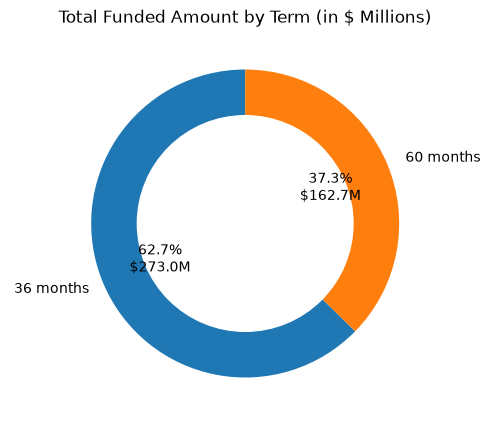

In [69]:
term_funding_millions = df.groupby('term')['loan_amount'].sum() / 1000000

plt.figure(figsize=(5, 5))
plt.pie(
    term_funding_millions,
    labels=term_funding_millions.index,
    autopct=lambda p: f"{p:.1f}%\n${p*sum(term_funding_millions)/100:.1f}M",
    startangle=90,
    wedgeprops={'width': 0.4}
)
plt.gca().add_artist(plt.Circle((0, 0), 0.70, color='white'))
plt.title("Total Funded Amount by Term (in $ Millions)")
plt.show()

### Employee Length by Total Funded Amount

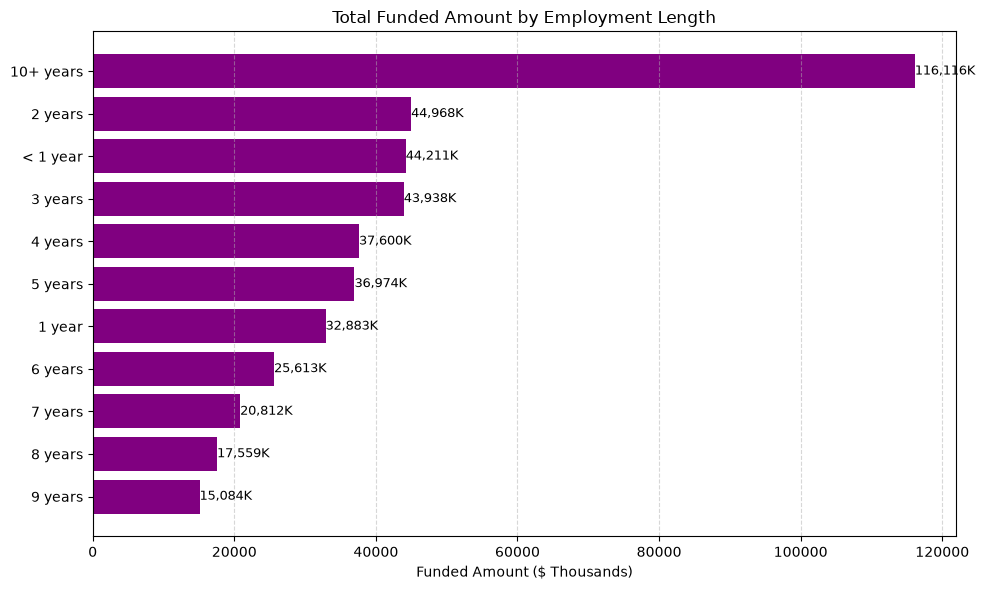

In [73]:
emp_funding_thousands = df.groupby('emp_length')['loan_amount'].sum().sort_values()/1000

plt.figure(figsize=(10, 6))
bars = plt.barh(emp_funding_thousands.index, emp_funding_thousands, color='purple')

for bar in bars:
    width = bar.get_width()
    plt.text(width + 5, bar.get_y() + bar.get_height() / 2,
             f"{width:,.0f}K", va='center', fontsize=9)

plt.xlabel('Funded Amount ($ Thousands)')
plt.title("Total Funded Amount by Employment Length")
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### Loan Purpose by Total Funded Amount

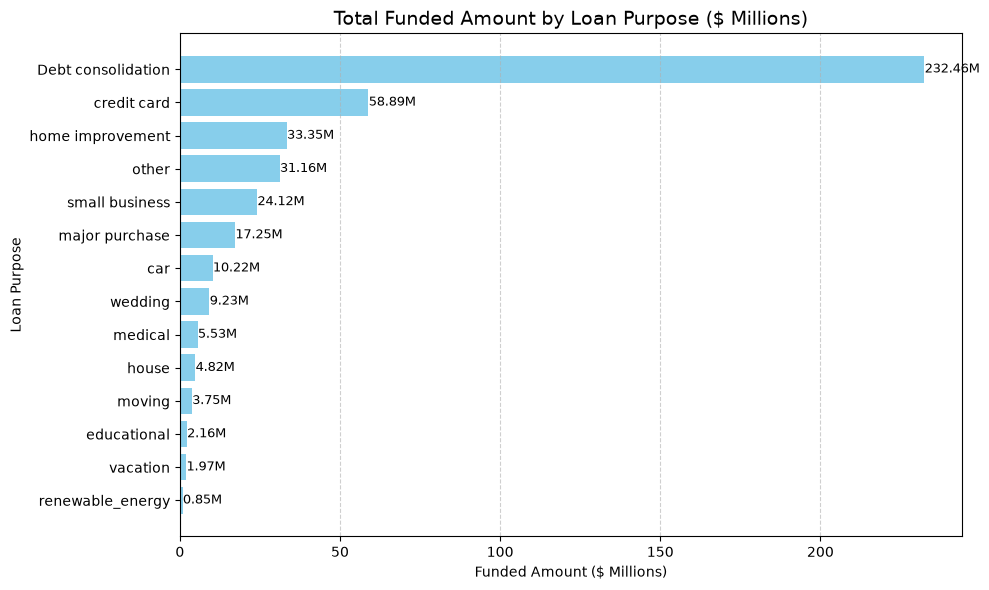

In [75]:
purpose_funding_millions = (df.groupby('purpose')['loan_amount'].sum().sort_values() / 1000000)

plt.figure(figsize=(10, 6))
bars = plt.barh(purpose_funding_millions.index, purpose_funding_millions.values, color='skyblue')

for bar in bars:
    width = bar.get_width()
    plt.text(width + 0.1, bar.get_y() + bar.get_height()/2,
             f'{width:.2f}M', va='center', fontsize=9)

plt.title('Total Funded Amount by Loan Purpose ($ Millions)', fontsize=14)
plt.xlabel('Funded Amount ($ Millions)')
plt.ylabel('Loan Purpose')
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

### Home Ownership by Total Funded Amount

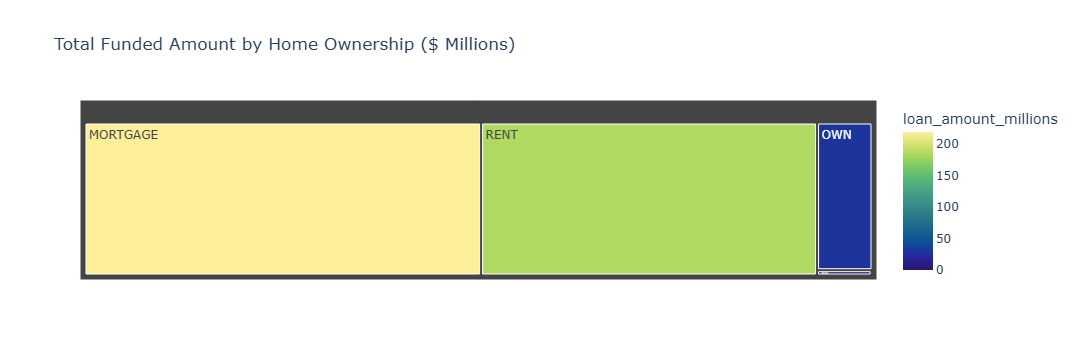

In [92]:
home_funding = df.groupby('home_ownership')['loan_amount'].sum().reset_index()
home_funding['loan_amount_millions'] = home_funding['loan_amount'] / 1_000_000

fig = px.treemap(
    home_funding,
    path=['home_ownership'],
    values='loan_amount_millions',
    color='loan_amount_millions',
    color_continuous_scale='haline',
    title='Total Funded Amount by Home Ownership ($ Millions)'
)
fig.show()
# 'aggrnyl', 'agsunset', 'algae', 'amp', 'armyrose', 'balance','blackbody', 'bluered', 'blues', 'blugrn', 'bluyl', 'brbg',
#'brwnyl', 'bugn', 'bupu', 'burg', 'burgyl', 'cividis', 'curl','darkmint', 'deep', 'delta', 'dense', 'earth', 'edge', 'electric',
#'emrld', 'fall', 'geyser', 'gnbu', 'gray', 'greens', 'greys','haline', 'hot', 'hsv', 'ice', 'icefire', 'inferno', 'jet',
#'magenta', 'magma', 'matter', 'mint', 'mrybm', 'mygbm', 'oranges', 'orrd', 'oryel', 'oxy', 'peach', 'phase', 'picnic', 'pinkyl',
#'piyg', 'plasma', 'plotly3', 'portland', 'prgn', 'pubu', 'pubugn','puor', 'purd', 'purp', 'purples', 'purpor', 'rainbow', 'rdbu',
#'rdgy', 'rdpu', 'rdylbu', 'rdylgn', 'redor', 'reds', 'solar','spectral', 'speed', 'sunset', 'sunsetdark', 'teal', 'tealgrn',
#'tealrose', 'tempo', 'temps', 'thermal', 'tropic', 'turbid','turbo', 'twilight', 'viridis', 'ylgn', 'ylgnbu', 'ylorbr','ylorrd'].